# Measuring US landfall

The main check of CHAZ against observations on the US coast is how strong storms are when they
come ashore. This notebook compares four ways of measuring it, on IBTrACS, the CHAZ team's ERA5 set
and two of our ERA5 runs: 'shipped', with the public code's settings, and 'refit-basin', the
configuration our runs use ([intensity.ipynb](intensity.ipynb)). It then checks the observed counts
against HURDAT's own landfall records.

The measure matters because neither record gives the wind at the moment of landfall. Observed
tracks have a position and wind every 6 hours. CHAZ predicts intensity every 12 hours, at even
nodes, and stores the mean of two predictions at the odd node between them. Between nodes a track
is interpolated, so the wind at the hour a storm crosses the coast is partly the wind of the next
node, which is often over land and weaker. Observed storms and CHAZ members also weaken at
different rates over land ([tracks.ipynb](tracks.ipynb), section 2), so the interpolation lowers
their landfall winds by different amounts.

The four measures count landfalls on the US Atlantic and Gulf coasts over 1981–2019
(`ocr.risks.hurricane.landfall`):

- **Strongest crossing, last offshore wind.** The other notebooks use this one. A crossing is an
  hour on US land after an hour over water, on the Natural Earth 1:10m US outline at 1/24°. A cell
  counts as US land if any part of the US falls in it, so the Florida Keys count. The crossing's wind is
  the member's wind at the last even node before it, at most 12 hours earlier, provided the storm
  stays over water from that node to the crossing. For CHAZ that is the last wind the intensity model
  predicted; IBTrACS is sampled the same way, at every other synoptic record. Each storm counts
  once, at its strongest crossing.
- **First crossing, wind at the crossing hour.** Each storm counts once, at the hourly
  interpolated wind of its first crossing.
- **Lee et al. (2018), every landfall.** The rule of the CHAZ paper's section 2.2: tracks and winds
  interpolated to 15 minutes, land from a 0.5° mask that marks a cell as land when its centre is on
  Natural Earth land (they used topography), and every landfall at least 100 km and 6 hours from the last one
  counted, at its interpolated wind.
- **Within 300 km of the coast.** Each storm's strongest wind at an even node within 300 km of US
  Atlantic or Gulf land. It needs no crossing, so it does not depend on when the track meets the
  coast.

Rates are per year, and CHAZ's per member-year (400 members a year).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ocr.risks.hurricane import landfall, store

R = 'TCGI_CRH_PI'
SETS = {
    'IBTrACS': 'rows_ibtracs',
    'CHAZ team': 'rows_published',
    'shipped': f'rows_ours_{R}',
    'refit-basin': f'rows_ours_{R}-land-fine-intensity-refit-basin',
}
COLORS = {
    'IBTrACS': '#52514e',
    'CHAZ team': '#eb6834',
    'shipped': '#2a78d6',
    'refit-basin': '#1baf7a',
}
THRESHOLDS = (34, 64, 96)
YEARS = landfall.YEARS[1] - landfall.YEARS[0] + 1
plt.rcParams.update(
    {'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110, 'font.size': 9}
)
rows = {k: pd.read_parquet(store.path(f'{landfall.OUT}/{v}.parquet')) for k, v in SETS.items()}
member_years = {
    k: YEARS * (1 if k == 'IBTrACS' else r.groupby('unit')['member'].nunique().sum())
    for k, r in rows.items()
}
pd.Series(member_years, name='member-years')

IBTrACS           39
CHAZ team      15600
shipped        15600
refit-basin    15600
Name: member-years, dtype: int64

## 1. Four measures

The first table gives the rates and the second gives CHAZ over IBTrACS, with and without the scaling
to the observed North Atlantic storm count that the other notebooks apply.

In [2]:
MEASURES = {
    'first crossing, wind at the crossing hour': lambda a, r, t: (a['lf_first_wind'] >= t).sum(),
    'strongest crossing, last offshore wind': lambda a, r, t: (a['lf_wind'] >= t).sum(),
    'Lee et al. (2018), every landfall': lambda a, r, t: r[f'lee_{t}'].sum(),
    f'within {landfall.NEAR_KM:.0f} km of the coast': lambda a, r, t: (r['near_peak'] >= t).sum(),
}
counts = {}
for name, r in rows.items():
    a = r[landfall.atlantic_crossing(r)]
    for m, f in MEASURES.items():
        for t in THRESHOLDS:
            counts[(m, f'≥ {t} kt', name)] = f(a, r, t) / member_years[name]
per_year = pd.Series(counts).unstack()[list(SETS)]
na = pd.Series({name: r['na_ts'].sum() / member_years[name] for name, r in rows.items()})
pd.concat([per_year, na.to_frame(('North Atlantic tropical storms', '')).T]).style.format(
    '{:.2f}'
).set_caption('US Atlantic and Gulf landfalls per year, 1981-2019 (CHAZ: per member-year)')

In [3]:
ratio = per_year.div(per_year['IBTrACS'], axis=0)
chaz = [k for k in SETS if k != 'IBTrACS']
table = pd.concat(
    {
        'not scaled': ratio[chaz],
        'scaled to the observed NA storm count': ratio[chaz] * (na['IBTrACS'] / na[chaz]),
    },
    axis=1,
)
table.style.format('{:.2f}').set_caption('CHAZ over IBTrACS')

The measures disagree most at 96 kt. With the last offshore wind, refit-basin makes 0.85 of the
observed hurricane landfalls and 0.70 of the major ones without the scaling, and 0.81 and 0.66
with it. Without the scaling, reading the wind at the hour of the first crossing gives refit-basin
0.66 and 0.50, and the Lee et al. rule gives it 0.71 and 0.52. These rules differ from ours both in
when they read the wind and in which crossings they count, and both put refit-basin further below
observed. Within 300 km of the coast, refit-basin has 1.10 of the observed storms at 34 kt, 0.92
at 64 kt and 0.73 at 96 kt, without the scaling.

Every measure puts the CHAZ team's set furthest from observed. At 64 kt every measure puts
refit-basin closer than shipped without the scaling; with it, the Lee et al. rule puts the two
level (0.68). At 96 kt every CHAZ set falls short.

Thirty-nine years give few landfalls, so part of any difference is sampling noise. Emanuel (2025)
tests model counts against it: the observed count is taken as one draw from a Poisson distribution
centred on the count the model expects, and the model passes where the count falls between that
distribution's 5th and 95th percentiles. He counts each storm's first sea-to-land crossing at the
wind interpolated to the crossing time, which is our first-crossing measure; John et al. (2026)
test CHAZ the same way. The test treats landfalls as independent from year to year, and
clustering between years would widen the bands. The one-sided p is the chance of a count at least
as far from the expected count as the observed one, on the same side of it.

In [4]:
from scipy import stats

PERIODS = {'1981-2019': (1981, 2019), '1981-1999': (1981, 1999), '2000-2019': (2000, 2019)}
SET = 'refit-basin'
per_member_year = member_years[SET] / YEARS  # members a year


def in_period(r, years):
    return r[r['year'].between(*years)]


def count(r, m, t):
    return MEASURES[m](r[landfall.atlantic_crossing(r)], r, t)


test = {}
for period, years in PERIODS.items():
    obs, syn = in_period(rows['IBTrACS'], years), in_period(rows[SET], years)
    scale = obs['na_ts'].sum() / (syn['na_ts'].sum() / per_member_year)
    for m in MEASURES if period == '1981-2019' else ['strongest crossing, last offshore wind']:
        for t in (64, 96):
            n = count(obs, m, t)
            for scaling, factor in (('not scaled', 1.0), ('scaled', scale)):
                lam = count(syn, m, t) / per_member_year * factor
                lo, hi = stats.poisson.ppf([0.05, 0.95], lam)
                p_one = stats.poisson.sf(n - 1, lam) if n >= lam else stats.poisson.cdf(n, lam)
                test[(period, m, f'≥ {t} kt', scaling)] = {
                    'observed': n,
                    'CHAZ expects': lam,
                    '5%': lo,
                    '95%': hi,
                    'inside': lo <= n <= hi,
                    'one-sided p': p_one,
                }
test = pd.DataFrame(test).T
test.style.format(
    {
        'observed': '{:.0f}',
        'CHAZ expects': '{:.1f}',
        '5%': '{:.0f}',
        '95%': '{:.0f}',
        'one-sided p': '{:.3f}',
    }
).set_caption(
    f'Observed US Atlantic and Gulf landfall counts against the 5th-95th percentiles of a Poisson'
    f' distribution centred on the count {SET} expects (Emanuel 2025)'
)

With the last offshore wind, refit-basin's US hurricane and major landfall counts over 1981–2019
fall inside the band, scaled or not (one-sided p from 0.072 to 0.133), and so do those of
2000–2019. In 1981–1999 the observed hurricane count, 27, sits at the top of the unscaled band of 13 to 27.
Scaling to the observed North Atlantic storm count lowers the expected count from 19.4 to 16.3,
and the observed count then falls outside the band (p = 0.009). With the first-crossing and Lee et
al. measures the observed counts lie above the band at both thresholds (p of 0.034 or less).
Within 300 km of the coast, the counts are inside the band at 64 kt and at its upper edge at
96 kt, just outside when scaled (p = 0.044).

Emanuel (2025) also scores the share of a basin's storms that cross a coast: he divides the
model's share by the observed share and counts a ratio of 0.75 to 1.25 as good. The scaled ratios
in section 1 are this ratio for US Atlantic and Gulf landfalls, with the basin's storms counted
from 34 kt.

Under the first-crossing and Lee et al. rules, part of the gap could come from how the two records
are spaced in time rather than from CHAZ. CHAZ's winds are 12-hourly predictions with the mean of
two predictions between them, and IBTrACS's are 6-hourly records. The wind at the hour of the
crossing is interpolated partly from the next record, which is often over land. The further apart
the independent winds are, the more weight that later wind gets. The table repeats the counts with IBTrACS's
winds put in CHAZ's form: every other synoptic record kept, starting from the first record or
from the second, and each record between replaced by the mean of its two neighbours. Positions
stay 6-hourly, as CHAZ's are.

In [5]:
def twelve_hourly(w):
    """Winds as CHAZ stores them: each odd node the mean of its two neighbours."""
    out = w.copy()
    out[:, 1:-1:2] = 0.5 * (w[:, :-2:2] + w[:, 2::2])
    if w.shape[1] % 2 == 0:
        out[:, -1] = np.nan
    return out


land = landfall.USLand()
lat, lon, wind, season = landfall.observed_arrays(landfall.ibtracs_csv(store.s3()))
thinned = {
    f'12-hourly from node {k}': landfall.storm_rows(
        lat[k:], lon[k:], twelve_hourly(wind[:, k:]), season, land, 'IBTrACS', 'ibtracs'
    )
    for k in (0, 1)
}
RULES = list(MEASURES)[:3]
syn = rows[SET]
scale = rows['IBTrACS']['na_ts'].sum() / (syn['na_ts'].sum() / per_member_year)
spacing = {}
for m in RULES:
    for t in (64, 96):
        for scaling, factor in (('not scaled', 1.0), ('scaled', scale)):
            lam = count(syn, m, t) / per_member_year * factor
            lo, hi = stats.poisson.ppf([0.05, 0.95], lam)
            row = {'IBTrACS 6-hourly': count(rows['IBTrACS'], m, t)}
            for name, r in thinned.items():
                n = count(r, m, t)
                row[f'IBTrACS {name}'] = n
                row[f'p, {name}'] = (
                    stats.poisson.sf(n - 1, lam) if n >= lam else stats.poisson.cdf(n, lam)
                )
            spacing[(m, f'≥ {t} kt', scaling)] = row | {f'{SET} expects': lam, '5%': lo, '95%': hi}
spacing = pd.DataFrame(spacing).T
spacing.style.format('{:.0f}').format('{:.1f}', subset=[f'{SET} expects']).format(
    '{:.3f}', subset=[c for c in spacing if c.startswith('p, ')]
).set_caption(
    "Observed US Atlantic and Gulf landfalls with IBTrACS's winds at 6 hours and thinned to 12 hours"
    f' as CHAZ stores them, against the count {SET} expects and its Poisson 5th-95th percentiles'
)

IBTrACS 20261112


Thinning lowers the observed counts under both published rules, but at hurricane strength they stay
above the count refit-basin expects. With the first-crossing rule, observed hurricane landfalls fall
from 53 to 48 thinned from the first record and 45 from the second, against 34.8 expected. Thinned from the first record, the count stays above the band
(p = 0.020); thinned from the second, it sits at the band's top (p = 0.055); scaled, both lie
above it. With the Lee et al. rule they fall from 59 to 54 or 55, above the band of 32 to 53
either way. At 96 kt the thinned counts lie inside the band under both rules (6 to 9, against
5.0 and 5.8 expected). After thinning, the gap at 96 kt is within sampling noise and the gap at
64 kt is smaller, and under the published rules refit-basin still makes too few hurricane
landfalls.

Our rule's observed counts barely move with the thinning (55 or 54 at 64 kt, 16 or 17 at 96 kt).
Scaled, the major count thinned from the second record lies just above its band (17 against a top
of 16, p = 0.043).

## 2. Observed landfalls against HURDAT's landfall records

HURDAT adds a record at each US landfall with the best-track wind there, and IBTrACS keeps these
records (USA_RECORD 'L'). They check the observed side of the comparison without any of our rules.
Counting each storm at its strongest landfall record within 25 km of US Atlantic or Gulf land:

In [6]:
records = landfall.landfall_records(landfall.ibtracs_csv(store.s3()), land)
best = records.groupby('storm').agg(
    season=('SEASON', 'first'), name=('NAME', 'first'), hurdat=('wind', 'max')
)
obs = rows['IBTrACS']
obs = obs[landfall.atlantic_crossing(obs)].set_index('storm')
both = best.join(obs[['lf_wind', 'lf_first_wind', 'lee_64', 'lee_96']], how='outer')
both['season'] = both['season'].fillna(0).astype(int)
pd.DataFrame(
    {
        f'≥ {t} kt': {
            'HURDAT landfall record': (both['hurdat'] >= t).sum(),
            'strongest crossing, last offshore wind': (both['lf_wind'] >= t).sum(),
            'first crossing, wind at the crossing hour': (both['lf_first_wind'] >= t).sum(),
            'both HURDAT and the last offshore wind': (
                (both['hurdat'] >= t) & (both['lf_wind'] >= t)
            ).sum(),
        }
        for t in (64, 96)
    }
).style.set_caption('Observed storms with a US Atlantic or Gulf landfall, 1981-2019')

IBTrACS 20261112


,≥ 64 kt,≥ 96 kt
HURDAT landfall record,58,17
"strongest crossing, last offshore wind",55,16
"first crossing, wind at the crossing hour",53,10
both HURDAT and the last offshore wind,55,15


In [7]:
def cls(w):
    return np.select([w >= 96, w >= 64], ['≥ 96', '64–96'], '< 64')


differ = both[cls(both['hurdat'].fillna(0)) != cls(both['lf_wind'].fillna(0))]
differ = differ[(differ['hurdat'] >= 64) | (differ['lf_wind'] >= 64)]
differ[['season', 'name', 'hurdat', 'lf_wind', 'lf_first_wind']].sort_values('season').style.format(
    {'hurdat': '{:.0f}', 'lf_wind': '{:.0f}', 'lf_first_wind': '{:.0f}'}, na_rep='–'
).hide(axis='index').set_caption(
    'Storms whose class differs between the HURDAT landfall record and the last offshore wind (kt)'
)

season,name,hurdat,lf_wind,lf_first_wind
1983,ALICIA,100,95,93
1987,FLOYD,65,60,65
2002,LILI,80,105,73
2004,CHARLEY,130,95,108
2005,CINDY,65,60,55
2019,DORIAN,85,–,–


HURDAT has 58 storms with a landfall at 64 kt or more and 17 at 96 kt or more. The last offshore
wind finds 55 and 16, and all 55 hurricanes and 15 of the 16 majors are also in HURDAT's counts.
Reading the wind at the hour of the first crossing finds 53 and 10.

Most of the storms whose class differs fit the 12-hour spacing of the winds. Charley (2004) counts
at 95 kt against HURDAT's 130 and Alicia (1983) at 95 against 100, as a storm that strengthened
after its last 12-hourly wind would. Lili (2002) counts at 105 against 80, as one that weakened
would. Floyd
(1987) and Cindy (2005) count at 60 against 65. For Dorian (2019) no crossing is found: every hourly
position of its track past Cape Hatteras falls over water.

## 3. Return periods by coast

Lee et al. (2018) present hazard as return-period curves of landfall wind by coast. To separate
how often storms come ashore from how strong they are, they also shift the simulated curves so
that the rate at the lowest threshold matches the observed one. The figure does both with the last
offshore wind. The Gulf coast is Texas to Alabama and Florida west of 81°W, and the Atlantic coast
is the rest. The top row is as run; in the bottom row each CHAZ set's rate at 34 kt is matched to
IBTrACS on each coast.

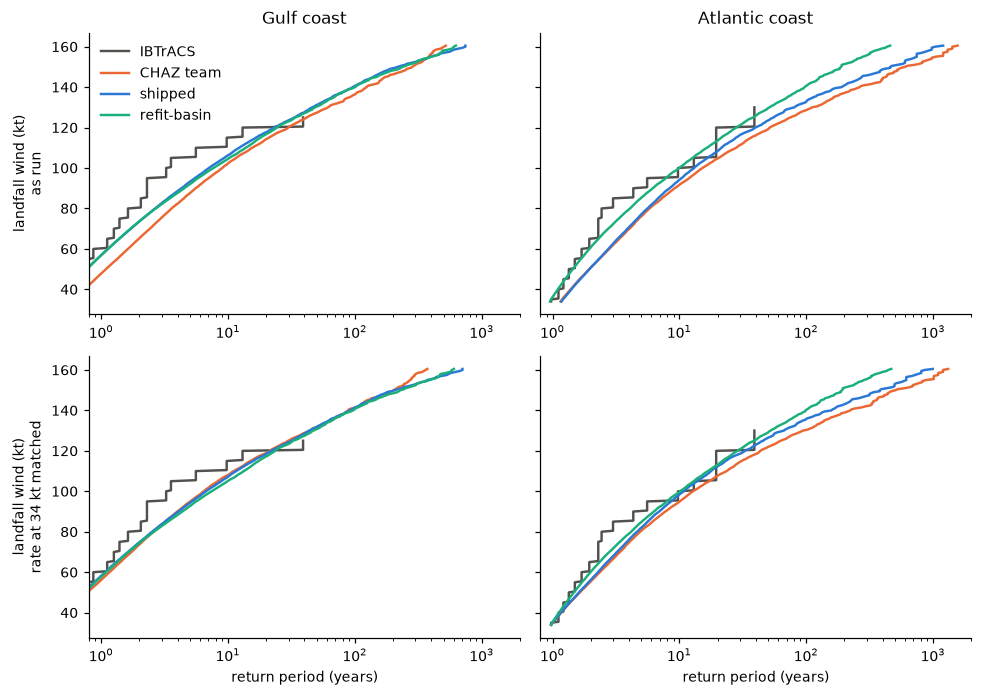

In [8]:
def coast(r):
    a = r[landfall.atlantic_crossing(r) & (r['lf_wind'] >= landfall.TS)]
    gulf = (a['lf_region'] == 'TX-AL') | ((a['lf_region'] == 'FL') & (a['lf_lon'] < -81.0))
    return {'Gulf coast': a[gulf], 'Atlantic coast': a[~gulf]}


levels = np.arange(34, 161, 0.5)
curves = {}
fig, axes = plt.subplots(2, 2, figsize=(9, 6.4), sharey=True)
obs_ts = {c: len(a) / member_years['IBTrACS'] for c, a in coast(rows['IBTrACS']).items()}
for name, r in rows.items():
    for j, (c, a) in enumerate(coast(r).items()):
        n = np.array([(a['lf_wind'] >= v).sum() for v in levels], float)
        for i, adjust in enumerate((1.0, obs_ts[c] / (len(a) / member_years[name]))):
            rate = n / member_years[name] * adjust
            curves[(c, ('as run', 'rate at 34 kt matched')[i], name)] = rate
            ok = rate > 0
            axes[i, j].plot(1 / rate[ok], levels[ok], color=COLORS[name], lw=1.6, label=name)
for j, c in enumerate(obs_ts):
    axes[0, j].set_title(c)
for ax in axes.flat:
    ax.set_xscale('log')
    ax.set_xlim(0.8, 2000)
axes[0, 0].set_ylabel('landfall wind (kt)\nas run')
axes[1, 0].set_ylabel('landfall wind (kt)\nrate at 34 kt matched')
for ax in axes[1]:
    ax.set_xlabel('return period (years)')
axes[0, 0].legend(frameon=False)
fig.tight_layout()

In [9]:
def wind_at(rate, period):
    """Landfall wind reached once in `period` years: where the exceedance rate falls to 1/period."""
    return np.interp(1 / period, rate[::-1], levels[::-1]) if rate[0] >= 1 / period else np.nan


PERIODS = (5, 10, 20)
pd.DataFrame(
    {
        key: {f'{p} years': wind_at(rate, p) for p in PERIODS}
        for key, rate in curves.items()
        if (key[1] == 'rate at 34 kt matched') != (key[2] == 'IBTrACS')
    }
).T.droplevel(1).style.format('{:.0f}').set_caption(
    'Landfall wind (kt) reached once per return period, CHAZ with its rate at 34 kt matched to'
    ' IBTrACS on each coast'
)

,,5 years,10 years,20 years
Gulf coast,IBTrACS,105,115,120
Atlantic coast,IBTrACS,90,100,120
Gulf coast,CHAZ team,95,108,119
Atlantic coast,CHAZ team,80,95,108
Gulf coast,shipped,94,107,119
Atlantic coast,shipped,82,98,112
Gulf coast,refit-basin,93,105,117
Atlantic coast,refit-basin,85,100,113


With the rate at 34 kt matched, the CHAZ sets come ashore on the Gulf coast about 10 kt weaker than
observed at return periods of 5 and 10 years: refit-basin reaches 93 and 105 kt against 105 and
115 observed. At 20 years it comes within a few knots (117 against 120). On the Atlantic coast
refit-basin is within 5 kt at 5 and 10 years (85 and 100 against 90 and 100), and every CHAZ set
falls short at 20 years (108–113 against 120), where 39 years of observations give about two
storms.

## Summary

The other notebooks count each storm's US landfall at its strongest crossing and read the wind
there from the last offshore wind. On the observed side, this measure comes within three storms of
HURDAT's landfall records at 64 kt and within one at 96 kt; reading the wind at the hour of the
first crossing finds 10 majors, against HURDAT's 17.

With the last offshore wind and without the North Atlantic scaling, refit-basin makes 0.85 of the
observed US hurricane landfalls and 0.70 of the major ones. Over 1981–2019 both counts lie inside
the 5th–95th percentile band of Poisson sampling noise that Emanuel (2025) tests against, so under
this rule 39 years of landfalls are too few to tell refit-basin's counts from the observed ones.
On the Gulf coast, once each CHAZ set's landfall rate at 34 kt is matched to the observed rate, its
storms come ashore about 10 kt weaker than observed at return periods of 5 and 10 years; on the
Atlantic coast refit-basin is within 5 kt at those return periods.

Under the first-crossing rule of Emanuel (2025) and John et al. (2026), and under the rule of Lee
et al. (2018), the observed counts lie above the band at 64 and 96 kt. With IBTrACS's winds thinned
to CHAZ's 12-hour spacing, the major counts fall inside the band, while the hurricane counts stay
above it or at its top. Under those rules refit-basin makes too few hurricane landfalls, and the
time spacing explains only part of the gap.

The measure has two known limits. Winds 12 hours apart miss strengthening or weakening in the last
hours before landfall (Charley, Lili), and a landfall on narrow land between two hourly positions
over water is missed (Dorian).